<font size=6>Import the libraries</font>

In [123]:

import tensorflow as tf
import cv2 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report , confusion_matrix
from mlxtend.plotting import plot_confusion_matrix
from PIL import Image


<font size=6>Loading the dataset</font>

In [103]:

dataset_path = Path("dataset")

IMG_SIZE = (128, 128)

x = []
y = []

classes = {
    "apple": 0,
    "orange": 1
}

for class_name, label in classes.items():

    folder = dataset_path / class_name

    for image_path in folder.iterdir():

        if not image_path.is_file():
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, IMG_SIZE)
        x.append(image)
        y.append(label)

x = np.array(x, dtype=np.float32) /255.0
y = np.array(y, dtype=np.int32)

x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

print("X shape:", x.shape)
print("y shape:", y.shape)

print("X dtype:", x.dtype)
print("y dtype:", y.dtype)



X shape: (796, 128, 128, 3)
y shape: (796,)
X dtype: float32
y dtype: int32


<font size=6>Plot sample of data</font>

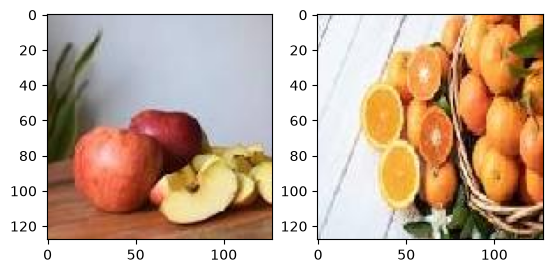

In [104]:
plt.subplot(1,2,1)
plt.imshow(x_train[5])
plt.subplot(1,2,2)
plt.imshow(x_train[300])

<font size=6>Design the CNN network</font>

In [105]:
data_augmentation = tf.keras.Sequential([

    # tf.keras.layers.RandomRotation(0.01),
    # tf.keras.layers.RandomTranslation(width_factor=0.01 , height_factor=0.01),
    tf.keras.layers.RandomBrightness(factor=0.01),
    tf.keras.layers.RandomContrast(factor=0.01),

])

In [106]:


tf.keras.utils.clear_session()
tf.random.set_seed(42)
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=[128,128,3]),
    
    tf.keras.layers.Conv2D(filters=16 , kernel_size=3 , padding="same" , strides=1 , activation="leaky_relu" , kernel_initializer="he_normal"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(pool_size=2),

    tf.keras.layers.Conv2D(filters=32 , kernel_size=3 , padding="same" , strides=1 , activation="leaky_relu" , kernel_initializer="he_normal"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(pool_size=2),

    tf.keras.layers.Dropout(rate=0.5),

    tf.keras.layers.Conv2D(filters=64 , kernel_size=3 , padding="same" , strides=2 , activation="leaky_relu" , kernel_initializer="he_normal"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(filters=64 , kernel_size=3 , padding="same" , strides=1 , activation="leaky_relu" , kernel_initializer="he_normal" ),
    tf.keras.layers.MaxPool2D(pool_size=2),

    tf.keras.layers.Conv2D(filters=128 , kernel_size=3 , padding="same" , strides=1 , activation="leaky_relu" , kernel_initializer="he_normal"),

    tf.keras.layers.Dropout(rate=0.5),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256 , activation="leaky_relu" , kernel_initializer="he_normal"),
    tf.keras.layers.Dropout(rate=0.4),
    tf.keras.layers.Dense(256 , activation="leaky_relu" , kernel_initializer="he_normal"),
    tf.keras.layers.Dropout(rate=0.4),

    tf.keras.layers.Dense(2 , activation="softmax")

])

<font size=6>Compile the model</font>

In [107]:
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy , metrics=["accuracy"] , optimizer=tf.keras.optimizers.SGD(learning_rate=0.001 , momentum=0.9 , nesterov=True))

<font size=6>Using callbacks</font>

In [108]:
def learning_rate(epoch):
    if epoch <= 2:
        return 0.001
    elif epoch > 2 and epoch <= 10:
        return 0.01
    elif epoch > 10 and epoch <= 50:
        return 0.001


learning_rate_schedule = tf.keras.callbacks.LearningRateScheduler(schedule=learning_rate)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy" , mode="max" , patience=10 , restore_best_weights=True)

<font size=6>Fit the model</font>

In [109]:
history = model.fit(x_train , y_train , epochs=50 , batch_size=32 , validation_split=0.2 , callbacks=[early_stopping ])

Epoch 1/50


I0000 00:00:1794190390.666699  180888 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_68710__.62


13/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5625 - loss: 1.9033

I0000 00:00:1794190394.874096  180893 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_68710__.62


16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 339ms/step - accuracy: 0.5709 - loss: 1.8492 - val_accuracy: 0.5000 - val_loss: 0.7905
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7264 - loss: 1.0024 - val_accuracy: 0.7422 - val_loss: 0.5512
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8071 - loss: 0.4989 - val_accuracy: 0.8125 - val_loss: 0.4763
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8307 - loss: 0.4086 - val_accuracy: 0.8828 - val_loss: 0.4242
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8287 - loss: 0.3952 - val_accuracy: 0.8828 - val_loss: 0.3875
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8740 - loss: 0.3238 - val_accuracy: 0.8594 - val_loss: 0.3463
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8780 - loss: 0.3233 - val_accuracy: 0.8750 - val_loss: 0.3333
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8642 - loss: 0.3176 - val_accuracy: 0.8750 - val_loss: 

<font size=6>Evaluate model on test data</font>

In [ ]:
y_pred = model.predict(x_test).argmax(axis=1)

print(classification_report(y_test , y_pred))


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step  
              precision    recall  f1-score   support

           0       0.97      0.93      0.95        75
           1       0.94      0.98      0.96        85

    accuracy                           0.96       160
   macro avg       0.96      0.95      0.96       160
weighted avg       0.96      0.96      0.96       160



<font size=6>Summary of model</font>

In [134]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,596,838 (17.54 MB)

 Trainable params: 2,298,306 (8.77 MB)

 Non-trainable params: 224 (896.00 B)

 Optimizer params: 2,298,308 (8.77 MB)

<font size=6>Plot learning curve of model</font>

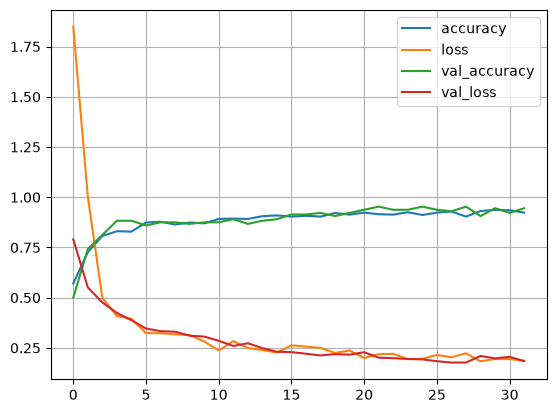

In [ ]:

plt.plot(pd.DataFrame(history.history) , label = history.history.keys())
plt.legend()
plt.grid()
# plt.savefig("learning_curve.png")

<font size=6>Plot confusion matrix of model</font>

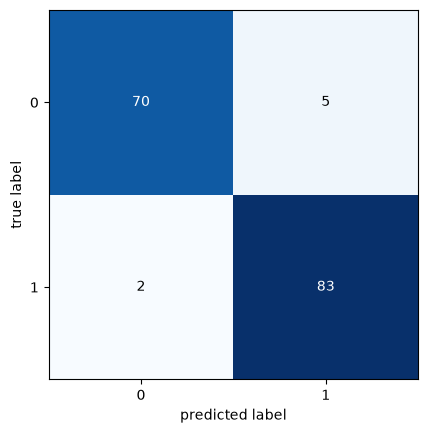

In [ ]:

cm = confusion_matrix(y_test , y_pred)

plot_confusion_matrix(cm)
# plt.savefig("confusion_matrix.png")

<font size=6>Evaluate model on outside of dataset'data</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
The predict of model is: [0]
the classes= apple:0  orange:1


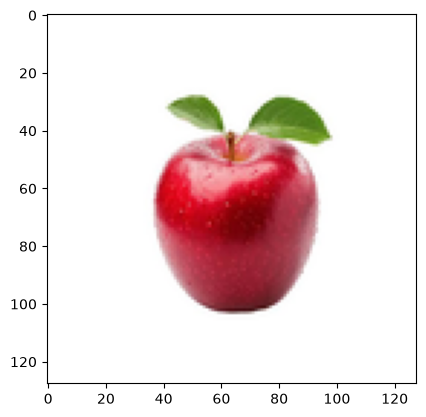

In [133]:

apple_img = Image.open("apple.jpg")
apple_img = apple_img.convert("RGB")
apple_img = apple_img.resize((128,128) , resample=Image.Resampling.LANCZOS)
apple_img = np.array(apple_img) / 255.0

plt.imshow(apple_img)
print(f"The predict of model is: {model.predict(apple_img.reshape(-1,128,128,3)).argmax(axis=1)}\nthe classes= apple:0  orange:1")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
The predict of model is: [1]
the classes= apple:0  orange:1


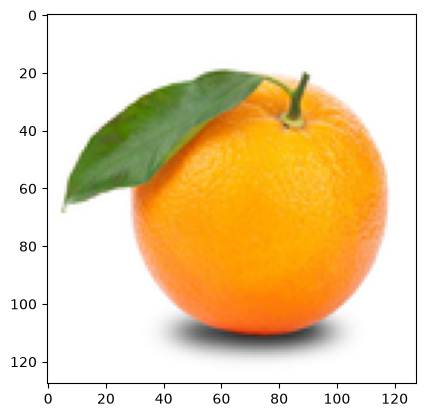

In [132]:
apple_img = Image.open("orange.jpg")
apple_img = apple_img.convert("RGB")
apple_img = apple_img.resize((128,128) , resample=Image.Resampling.LANCZOS)
apple_img = np.array(apple_img) / 255.0

plt.imshow(apple_img)
print(f"The predict of model is: {model.predict(apple_img.reshape(-1,128,128,3)).argmax(axis=1)}\nthe classes= apple:0  orange:1")